# Do Climate Anomalies Improve Short-Term Vegetation Forecasts Beyond Persistence? Pothohar Region, Pakistan (v3)
**Author:** Malaika Noor | **Tools:** scikit-learn, pandas (data from Google Earth Engine)

## Why a third version
- **v1** (raw VCI, one 2019-2025 test period): almost no skill.
- **v2** (anomalies against a fixed 2001-2017 baseline): the test years looked "above normal" because NDVI in these districts drifts upward over 25 years. That made "skill versus climatology" misleading and a fixed baseline the wrong choice.
- **v3** fixes the design flaw that v2 exposed. This design was chosen *after* seeing v1 and v2 results, and that is stated openly in the write-up.

## Design (fixed in advance; each result is computed once)
1. **Trailing baseline:** anomalies are computed against the previous 10 years only, per district and calendar month. This removes the long-term drift without using future data.
2. **Rolling-origin evaluation:** for each test year 2015-2025, models are trained only on data whose forecast target lies before that year, then predict that year. This gives 11 independent test years instead of one block.
3. **Primary question:** *do climate anomalies (rainfall, soil moisture, temperature) improve forecasts of NDVI anomaly 1-3 months ahead beyond an autoregressive model that uses vegetation history alone?* Primary metric: skill = 1 - MSE(with climate) / MSE(NDVI only), with a bootstrap confidence interval over test years.
4. **Baselines:** persistence (anomaly stays as is) and climatology (anomaly = 0).
5. No hyper-parameter tuning on test years; models use fixed settings.
6. Seasonal results are **exploratory** and labelled so.

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.makedirs('results', exist_ok=True)

CSV = 'monthly_district_data.csv'
if not os.path.exists(CSV):
    from google.colab import files
    print('Upload monthly_district_data.csv (from your Project 1 results folder)')
    up = files.upload()
    CSV = list(up.keys())[0]
raw = pd.read_csv(CSV)
print(raw.shape, list(raw.district.unique()))

Upload monthly_district_data.csv (from your Project 1 results folder)


Saving monthly_district_data.csv to monthly_district_data.csv
(1200, 6) ['Attock', 'Rawalpindi', 'Chakwal', 'Jhelum']


In [9]:
import shutil
from google.colab import files
shutil.make_archive('results_project1_v3', 'zip', 'results')
files.download('results_project1_v3.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 1. Trailing-baseline anomalies and features

In [2]:
VARS = ['ndvi', 'precip', 'temp', 'soil_moisture']
df = raw.copy()
df['date'] = pd.to_datetime(df['date'])
df['month'] = df.date.dt.month; df['year'] = df.date.dt.year

# baseline = previous 10 years of the same district and calendar month (never the current or future years)
df = df.sort_values(['district', 'month', 'year']).reset_index(drop=True)
gm = df.groupby(['district', 'month'])
for v in VARS:
    mu = gm[v].transform(lambda s: s.shift(1).rolling(10, min_periods=8).mean())
    sd = gm[v].transform(lambda s: s.shift(1).rolling(10, min_periods=8).std())
    df[f'{v}_z'] = ((df[v] - mu) / sd.replace(0, np.nan)).clip(-4, 4)
df = df.sort_values(['district', 'date']).reset_index(drop=True)

g = df.groupby('district')
df['precip_z3'] = g['precip_z'].transform(lambda s: s.rolling(3).sum())
df['precip_z6'] = g['precip_z'].transform(lambda s: s.rolling(6).sum())
df['soil_z3'] = g['soil_moisture_z'].transform(lambda s: s.rolling(3).mean())
for v in ['ndvi_z', 'precip_z', 'temp_z', 'soil_moisture_z']:
    for L in (1, 2):
        df[f'{v}_lag{L}'] = g[v].shift(L)
df['month_sin'] = np.sin(2 * np.pi * df.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df.month / 12)
for lead in (1, 2, 3):
    df[f'target_{lead}'] = g['ndvi_z'].shift(-lead)
df = pd.concat([df, pd.get_dummies(df['district'], prefix='d', dtype=float)], axis=1)
DIST = [c for c in df.columns if c.startswith('d_')]

NDVI_ONLY = ['ndvi_z', 'ndvi_z_lag1', 'ndvi_z_lag2', 'month_sin', 'month_cos'] + DIST
CLIMATE = ['precip_z', 'precip_z_lag1', 'precip_z_lag2', 'precip_z3', 'precip_z6', 'temp_z', 'temp_z_lag1', 'temp_z_lag2',
           'soil_moisture_z', 'soil_moisture_z_lag1', 'soil_moisture_z_lag2', 'soil_z3']
ALL = NDVI_ONLY + CLIMATE

print('Yearly mean NDVI anomaly with the trailing baseline (should be close to 0, no long-term drift):')
print(df.groupby('year')['ndvi_z'].mean().round(2).dropna().to_string())

Yearly mean NDVI anomaly with the trailing baseline (should be close to 0, no long-term drift):
year
2009   -0.63
2010   -0.07
2011    0.70
2012   -0.12
2013    1.05
2014    0.95
2015    1.32
2016    0.45
2017    0.08
2018    0.27
2019    1.19
2020    1.31
2021    0.05
2022    0.39
2023    0.75
2024    0.43
2025    0.12


## 2. Rolling-origin evaluation (test years 2015-2025)

In [3]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

TEST_YEARS = list(range(2015, 2026))
alphas = np.logspace(-1, 3, 15)

def fit_predict(tr, te, lead):
    y = tr[f'target_{lead}']
    out = {}
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(tr[NDVI_ONLY], y)
    out['Ridge NDVI-only'] = m.predict(te[NDVI_ONLY])
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(tr[ALL], y)
    out['Ridge NDVI+climate'] = m.predict(te[ALL])
    m = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(tr[ALL], y)
    out['RandomForest NDVI+climate'] = m.predict(te[ALL])
    m = HistGradientBoostingRegressor(learning_rate=0.05, max_depth=3, max_iter=200, random_state=42).fit(tr[ALL], y)
    out['GradientBoosting NDVI+climate'] = m.predict(te[ALL])
    return out

parts = []
for lead in (1, 2, 3):
    d = df.dropna(subset=ALL + [f'target_{lead}']).copy()
    d['target_date'] = (d.date.dt.to_period('M') + lead).dt.to_timestamp()
    for Y in TEST_YEARS:
        tr = d[d.target_date < f'{Y}-01-01']
        te = d[d.year == Y]
        if len(tr) < 100 or len(te) == 0:
            continue
        preds = fit_predict(tr, te, lead)
        res = te[['district', 'date', 'month', 'year']].copy()
        res['lead'] = lead; res['y'] = te[f'target_{lead}'].values
        res['Persistence'] = te['ndvi_z'].values; res['Climatology (zero)'] = 0.0
        for k, v in preds.items():
            res[k] = v
        parts.append(res)
P = pd.concat(parts, ignore_index=True)
MODELS = ['Persistence', 'Climatology (zero)', 'Ridge NDVI-only', 'Ridge NDVI+climate',
          'RandomForest NDVI+climate', 'GradientBoosting NDVI+climate']
print(P.groupby('lead').size().to_string(), '\nrows per lead; test years:', sorted(P.year.unique()))

lead
1    524
2    520
3    516 
rows per lead; test years: [np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]


In [4]:
rows = []
for lead, d in P.groupby('lead'):
    mse_p = np.mean((d.y - d['Persistence']) ** 2); mse_0 = np.mean(d.y ** 2)
    for m in MODELS:
        e = d.y - d[m]
        rows.append(dict(lead_months=lead, model=m, RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)),
                         skill_vs_persistence=1 - np.mean(e ** 2) / mse_p, skill_vs_climatology=1 - np.mean(e ** 2) / mse_0))
metrics = pd.DataFrame(rows).round(3)
metrics.to_csv('results/metrics_v3.csv', index=False)
metrics.pivot(index='model', columns='lead_months', values='skill_vs_persistence')

lead_months,1,2,3
model,,,
Climatology (zero),-0.690,-0.023,0.155
GradientBoosting NDVI+climate,0.066,0.102,0.167
Persistence,0.000,0.000,0.000
RandomForest NDVI+climate,0.129,0.201,0.270
Ridge NDVI+climate,0.167,0.283,0.336
Ridge NDVI-only,0.144,0.276,0.331


Values above are **skill versus persistence**: 0 = no better than keeping the current anomaly, positive = better, negative = worse. Full RMSE/MAE table below.

In [5]:
metrics.sort_values(['lead_months', 'RMSE'])

,lead_months,model,RMSE,MAE,skill_vs_persistence,skill_vs_climatology
3,1,Ridge NDVI+climate,0.818,0.603,0.167,0.507
2,1,Ridge NDVI-only,0.829,0.616,0.144,0.494
4,1,RandomForest NDVI+climate,0.837,0.629,0.129,0.485
5,1,GradientBoosting NDVI+climate,0.867,0.656,0.066,0.447
0,1,Persistence,0.897,0.645,0.000,0.408
1,1,Climatology (zero),1.165,0.949,-0.690,0.000
9,2,Ridge NDVI+climate,0.978,0.761,0.283,0.299
8,2,Ridge NDVI-only,0.983,0.789,0.276,0.292
10,2,RandomForest NDVI+climate,1.032,0.815,0.201,0.219
11,2,GradientBoosting NDVI+climate,1.095,0.851,0.102,0.122


## 3. Primary question: do climate anomalies add skill beyond NDVI history alone?

In [6]:
rng = np.random.default_rng(42)
def boot_skill(d, a, b, n=5000):
    # skill of model a relative to model b, pooled, bootstrapping test years
    g_ = d.groupby('year').apply(lambda x: pd.Series({'sa': ((x.y - x[a]) ** 2).sum(), 'sb': ((x.y - x[b]) ** 2).sum()}), include_groups=False)
    est = 1 - g_.sa.sum() / g_.sb.sum()
    idx = np.arange(len(g_)); vals = []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True)
        vals.append(1 - g_.sa.values[s].sum() / g_.sb.values[s].sum())
    wins = int((g_.sa < g_.sb).sum())
    return est, np.percentile(vals, 2.5), np.percentile(vals, 97.5), wins, len(g_)

rows = []
for lead, d in P.groupby('lead'):
    for a, b, label in [('Ridge NDVI+climate', 'Ridge NDVI-only', 'climate adds to NDVI history (Ridge)'),
                        ('Ridge NDVI+climate', 'Persistence', 'Ridge with climate vs persistence'),
                        ('Ridge NDVI-only', 'Persistence', 'NDVI-history model vs persistence')]:
        est, lo, hi, w, n = boot_skill(d, a, b)
        rows.append(dict(lead_months=lead, comparison=label, skill=est, ci95_low=lo, ci95_high=hi, years_better=f'{w} of {n}'))
primary = pd.DataFrame(rows).round(3)
primary.to_csv('results/primary_comparison_v3.csv', index=False); primary

,lead_months,comparison,skill,ci95_low,ci95_high,years_better
0,1,climate adds to NDVI history (Ridge),0.027,-0.056,0.099,6 of 11
1,1,Ridge with climate vs persistence,0.167,0.040,0.269,8 of 11
2,1,NDVI-history model vs persistence,0.144,0.066,0.197,8 of 11
3,2,climate adds to NDVI history (Ridge),0.010,-0.056,0.091,5 of 11
4,2,Ridge with climate vs persistence,0.283,0.155,0.376,8 of 11
5,2,NDVI-history model vs persistence,0.276,0.150,0.360,9 of 11
6,3,climate adds to NDVI history (Ridge),0.008,-0.061,0.083,5 of 11
7,3,Ridge with climate vs persistence,0.336,0.192,0.445,9 of 11
8,3,NDVI-history model vs persistence,0.331,0.158,0.452,9 of 11


**How to read it:** if the 95% interval for "climate adds to NDVI history" is entirely above 0, climate variables add real skill; if it includes 0, the data do not show a reliable gain. Report it either way.

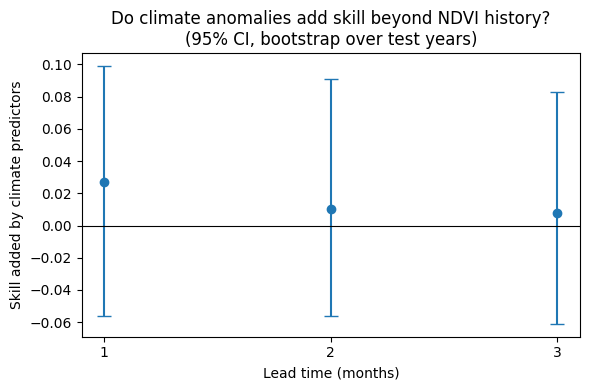

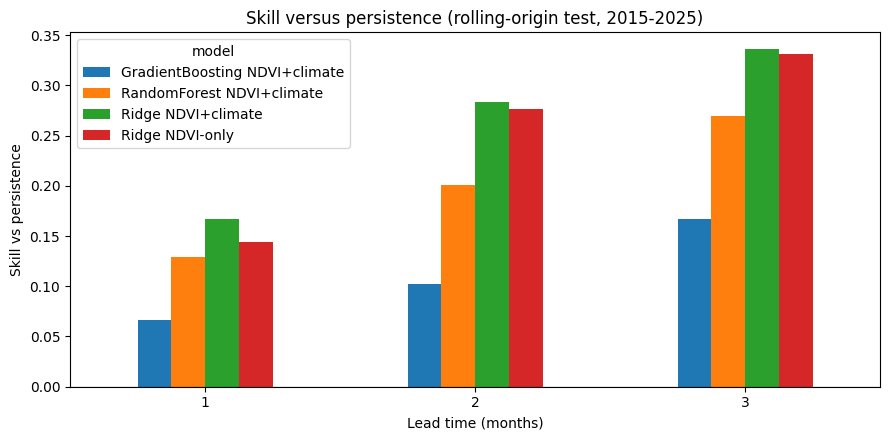

In [7]:
pr = primary[primary.comparison == 'climate adds to NDVI history (Ridge)']
plt.figure(figsize=(6, 4))
plt.errorbar(pr.lead_months, pr.skill, yerr=[pr.skill - pr.ci95_low, pr.ci95_high - pr.skill], fmt='o', capsize=5)
plt.axhline(0, color='k', lw=0.8); plt.xticks([1, 2, 3])
plt.xlabel('Lead time (months)'); plt.ylabel('Skill added by climate predictors')
plt.title('Do climate anomalies add skill beyond NDVI history?\n(95% CI, bootstrap over test years)')
plt.tight_layout(); plt.savefig('results/climate_added_skill_v3.png', dpi=200); plt.show()

sk = metrics.pivot(index='lead_months', columns='model', values='skill_vs_persistence').drop(columns=['Persistence', 'Climatology (zero)'])
sk.plot.bar(figsize=(9, 4.5), rot=0, title='Skill versus persistence (rolling-origin test, 2015-2025)')
plt.axhline(0, color='k', lw=0.8); plt.ylabel('Skill vs persistence'); plt.xlabel('Lead time (months)')
plt.tight_layout(); plt.savefig('results/skill_vs_persistence_v3.png', dpi=200); plt.show()

## 4. Exploratory: where does climate information help? (lead 1, by target season)

In [8]:
d = P[P.lead == 1].copy()
tm = (d.month % 12) + 1                        # month of the forecast target
d['season'] = np.select([tm.isin([12, 1, 2]), tm.isin([3, 4, 5]), tm.isin([6, 7, 8, 9])], ['Winter (Dec-Feb)', 'Spring (Mar-May)', 'Monsoon (Jun-Sep)'], 'Autumn (Oct-Nov)')
rows = []
for s, x in d.groupby('season'):
    a = ((x.y - x['Ridge NDVI+climate']) ** 2).sum(); b = ((x.y - x['Ridge NDVI-only']) ** 2).sum()
    rows.append(dict(season=s, n=len(x), skill_climate_added=1 - a / b))
season = pd.DataFrame(rows).round(3); season.to_csv('results/seasonal_exploratory_v3.csv', index=False); season

,season,n,skill_climate_added
0,Autumn (Oct-Nov),88,-0.203
1,Monsoon (Jun-Sep),176,-0.065
2,Spring (Mar-May),132,0.248
3,Winter (Dec-Feb),128,0.171


*Exploratory only: four seasonal comparisons were examined, so a single positive season is not strong evidence on its own.*

## 5. How to report this
- Report the design history (v1, v2, v3) openly, including that v3 was chosen after seeing v1/v2.
- Lead with the primary comparison and its confidence interval at each lead time, then persistence and climatology as baselines.
- State the finding plainly: either climate predictors add measurable skill (and at which lead times), or they do not.
- Limitations: district means, 1 km MODIS, no cropland mask, four districts, 11 test years, ERA5-Land/CHIRPS uncertainties, upward NDVI drift not explained.